# 06 - Data loader
- **Step 1 (PI2):** load the listeners' hearing-aid (compressor) settings
- **Step 2 (PI3 + PI4):** a documented, reusable loader that returns mixture, stems, audiogram, gains and compressor settings for any scene, plus checks on every valid scene
- **Step 3 (PI5):** find the real recordings and compare them with the synthetic ones

**Before this, run `00_shared_drive_data.ipynb`:** the Drive cell, the clone-Clarity cell and **Part A**. Run **Part B** too if you want the eval set (the only real recordings we have, see Step 3).

Note: this notebook uses paths in `/content`, so a Colab session restart means running 00 again.

1. Check prerequisites (nothing is downloaded here)

In [1]:
import os
from pathlib import Path
os.chdir('/content')

root = Path('/content/cadenza_data/cad2/task2')
clarity_dir = Path('/content/clarity')
meta = root / 'metadata'

need = {
    'Clarity (run 00 clone cell or 01_setup)': clarity_dir / 'recipes/cad2/task2/baseline/config.yaml',
    'valid metadata (run 00 Part A)': meta / 'scenes.valid.json',
    'valid audio (run 00 Part A)': root / 'audio/valid',
}
missing = [k for k, p in need.items() if not p.exists()]
assert not missing, 'Missing: ' + '; '.join(missing)

splits = [sp for sp in ['train', 'valid', 'eval'] if (meta / f'scenes.{sp}.json').exists()]
print('prerequisites ok | splits with metadata:', splits)
print('audio folders:', sorted(p.name for p in (root / 'audio').iterdir()))

prerequisites ok | splits with metadata: ['train', 'valid', 'eval']
audio folders: ['eval', 'train', 'valid']


2. Get the loader from the repo
The loader lives in `cadenza/cad2_loader.py` in our GitHub repo. This cell clones the repo (or pulls the latest version if it is already cloned) and imports it.
**To change the loader, edit `cadenza/cad2_loader.py`, push it, then re-run this cell.** Colab only sees what is pushed to the `new_model_creation` branch.

In [2]:
# Get the team repo (holds cadenza/cad2_loader.py): clone it the first time, update it after that
REPO = '/content/project'
BRANCH = 'new_model_creation'
if not Path(REPO).exists():
    !git clone -q -b {BRANCH} https://github.com/stevejo12/hearing-adaptive-music-processor.git {REPO}
else:   # throwaway copy: always match GitHub exactly
    !git -C {REPO} fetch -q origin {BRANCH} && git -C {REPO} checkout -q {BRANCH} && git -C {REPO} reset -q --hard origin/{BRANCH}
!git -C {REPO} log --oneline -1

import sys, json, importlib
# /content/clarity is the Clarity download folder; the real package is /content/clarity/clarity.
# Put the download folder first, otherwise Python (running in /content) mistakes it for the package.
if str(clarity_dir) not in sys.path:
    sys.path.insert(0, str(clarity_dir))
for m in [m for m in sys.modules if m == 'clarity' or m.startswith('clarity.')]:
    del sys.modules[m]                             # drop a wrong `clarity` remembered from an earlier run

loader_dir = Path(REPO) / 'cadenza'
assert (loader_dir / 'cad2_loader.py').exists(), f'cad2_loader.py not in {loader_dir} - is it pushed to {BRANCH}?'
if str(loader_dir) not in sys.path:
    sys.path.insert(0, str(loader_dir))
importlib.invalidate_caches()                      # forget that the folder looked empty before
import cad2_loader; importlib.reload(cad2_loader)   # use the newest version after a pull
from cad2_loader import CAD2Loader, mean_hearing_loss, clip_stats, stem_bleed
print('loader from', cad2_loader.__file__)

7180938 (HEAD -> new_model_creation, origin/new_model_creation) dung
loader from /content/project/cadenza/cad2_loader.py


3. Create the loader

In [3]:
loader = CAD2Loader(root, clarity_dir)
print('loader ready:', loader.root)

loader ready: /content/cadenza_data/cad2/task2


## Step 1 - Compressor settings (PI2)
Every listener has their own hearing-aid settings in `compressor_params.<split>.json`:
- `cr_l`, `cr_r` - **compression ratio** per ear (how much loud sounds are squashed)
- `gain_l`, `gain_r` - **makeup gain** per ear (how much everything is turned up)

The rest is the same for everyone and comes from the baseline `config.yaml`: crossover frequencies (band edges), attack, release and threshold per band.

1a. Look at the raw file

In [4]:
comp = loader.compressor_params('valid')
first_id = next(iter(comp))
print(len(comp), 'listeners in compressor_params.valid.json')
print(first_id, comp[first_id])

50 listeners in compressor_params.valid.json
L5076 {'frequencies': [250, 500, 1000, 2000, 4000, 8000], 'cr_l': [1.02470994644481, 1.01406359633136, 1.10566211398571, 1.20247566156274, 1.60742988411463, 2.83307104688178], 'gain_l': [0.0, 1.53444327214088, 9.59981745341322, 13.2158191689829, 16.1551108333714, 25.7742317168021], 'cr_r': [1.0271881118234, 1.08966838324609, 1.13420459109178, 1.23136048821063, 1.31760426235037, 2.49506862665294], 'gain_r': [0.0, 3.61101660918527, 10.1165243289266, 13.6000457919252, 14.1959225009387, 23.7940730980932]}


1b. Combine with the shared settings - the same structure `enhance.py` builds (`mbc_params_listener`)

In [5]:
import json
print('shared:', loader.shared_compressor_settings())
print(json.dumps(loader.get_compressor(first_id, 'valid'), indent=1))

shared: {'crossover_frequencies': [353.55, 707.11, 1414.21, 2828.43, 5656.85], 'attack': [11, 11, 14, 13, 11, 11], 'release': [80, 80, 80, 80, 100, 100], 'threshold': [-30, -30, -30, -30, -30, -30]}
{
 "crossover_frequencies": [
  353.55,
  707.11,
  1414.21,
  2828.43,
  5656.85
 ],
 "left": {
  "attack": [
   11,
   11,
   14,
   13,
   11,
   11
  ],
  "release": [
   80,
   80,
   80,
   80,
   100,
   100
  ],
  "threshold": [
   -30,
   -30,
   -30,
   -30,
   -30,
   -30
  ],
  "ratio": [
   1.02470994644481,
   1.01406359633136,
   1.10566211398571,
   1.20247566156274,
   1.60742988411463,
   2.83307104688178
  ],
  "makeup_gain": [
   0.0,
   1.53444327214088,
   9.59981745341322,
   13.2158191689829,
   16.1551108333714,
   25.7742317168021
  ]
 },
 "right": {
  "attack": [
   11,
   11,
   14,
   13,
   11,
   11
  ],
  "release": [
   80,
   80,
   80,
   80,
   100,
   100
  ],
  "threshold": [
   -30,
   -30,
   -30,
   -30,
   -30,
   -30
  ],
  "ratio": [
   1.02718811

1c. Every listener should have both an audiogram and compressor settings

In [6]:
for sp in splits:
    try:
        print(sp, loader.check_listener_match(sp))
    except FileNotFoundError as e:
        print(sp, 'skipped:', e)

train {'n_listeners': 83, 'n_compressor': 83, 'missing_compressor': [], 'missing_audiogram': []}
valid {'n_listeners': 50, 'n_compressor': 50, 'missing_compressor': [], 'missing_audiogram': []}
eval {'n_listeners': 51, 'n_compressor': 51, 'missing_compressor': [], 'missing_audiogram': []}


1d. Does worse hearing get more gain / more compression?
One point per valid listener. x = average audiogram level over both ears (dB HL, higher = worse hearing).

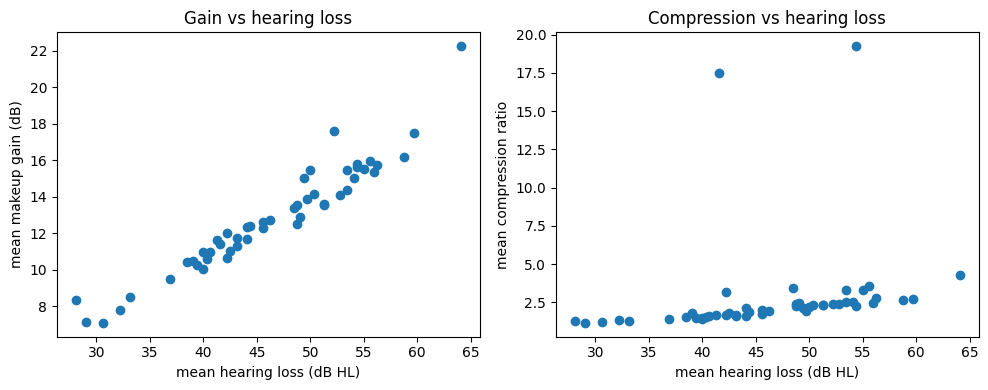

correlation  loss-gain: 0.96   loss-ratio: 0.22


In [7]:
import numpy as np
import matplotlib.pyplot as plt

listeners = loader.listeners('valid')
ids = [l for l in comp if l in listeners]
loss = [mean_hearing_loss(listeners[l]) for l in ids]
gain = [np.mean([comp[l]['gain_l'], comp[l]['gain_r']]) for l in ids]
ratio = [np.mean([comp[l]['cr_l'], comp[l]['cr_r']]) for l in ids]

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(loss, gain); ax[0].set(xlabel='mean hearing loss (dB HL)', ylabel='mean makeup gain (dB)', title='Gain vs hearing loss')
ax[1].scatter(loss, ratio); ax[1].set(xlabel='mean hearing loss (dB HL)', ylabel='mean compression ratio', title='Compression vs hearing loss')
plt.tight_layout(); plt.show()
print(f'correlation  loss-gain: {np.corrcoef(loss, gain)[0, 1]:.2f}   loss-ratio: {np.corrcoef(loss, ratio)[0, 1]:.2f}')

**Step 1 notes (fill in):**
- Keys per listener: ___ (per band or one value?)
- Listeners missing settings: ___
- Worse hearing -> more gain? ___ (correlation ___). More compression? ___

## Step 2 - Reusable data loader (PI3 + PI4)

How the files link together:

| From | File | Gives |
|---|---|---|
| scene_id | `scene_listeners.<split>.json` | which listeners hear this scene |
| scene_id | `scenes.<split>.json` | song name + gain id |
| song name | `music.<split>.json` | for mixture and each source: instrument, track path, start, duration |
| gain id | `gains.json` | dB change per source |
| listener_id | `listeners.<split>.json` | audiogram (left / right) |
| listener_id | `compressor_params.<split>.json` | hearing-aid settings (Step 1) |

`load_scene()` follows these links and returns everything in one dict. **Consistent format (PI3):** all audio is float32, stereo `(samples, 2)`, 44.1 kHz (or `target_sr`), same length, cut to the scene segment.

2a. Load one scene (same as notebooks 03 and 05)

In [8]:
s = loader.load_scene('S50001', split='valid')
for k, v in s.items():
    if isinstance(v, np.ndarray):
        print(f'{k:13s} array {v.shape} {v.dtype}')
    elif k == 'stems':
        print(f'{k:13s}', {kk: vv.shape for kk, vv in v.items()})
    elif k == 'listener':
        print(f'{k:13s} Listener {v.id}')
    elif k == 'compressor':
        print(f'{k:13s} left ratio {v["left"]["ratio"]}, left gain {v["left"]["makeup_gain"]}')
    else:
        print(f'{k:13s}', v)

scene_id      S50001
listener_id   L5051
split         valid
song          anitrasdance_001
song_seconds  15.0
sample_rate   44100
mixture       array (661500, 2) float32
stems         {'source_1': (661500, 2), 'source_2': (661500, 2), 'source_3': (661500, 2), 'source_4': (661500, 2)}
missing_stems []
instruments   {'source_1': 'Cello', 'source_2': 'Viola', 'source_3': 'Violin', 'source_4': 'Violin'}
gains         {'source_1': -6, 'source_2': 10, 'source_3': 3, 'source_4': 0}
listener      Listener L5051
compressor    left ratio [1.02225149351643, 1.0, 1.02861683957983, 1.11106031112138, 2.06071267012416, 2.69317636865938], left gain [0.0, 0.0, 7.88948561147926, 11.9521575089003, 18.1142991658042, 21.9229819958843]
dataset       EnsembleSet
origin        synthetic


2b. Look and listen: the listener's audiogram and the mixture

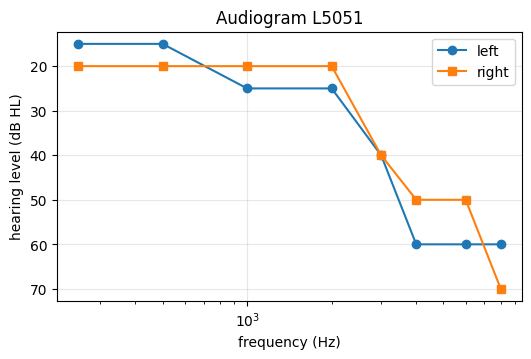

In [9]:
from IPython.display import Audio, display

lst = s['listener']
plt.figure(figsize=(6, 3.5))
plt.semilogx(lst.audiogram_left.frequencies, lst.audiogram_left.levels, 'o-', label='left')
plt.semilogx(lst.audiogram_right.frequencies, lst.audiogram_right.levels, 's-', label='right')
plt.gca().invert_yaxis(); plt.xlabel('frequency (Hz)'); plt.ylabel('hearing level (dB HL)')
plt.title(f'Audiogram {lst.id}'); plt.legend(); plt.grid(alpha=.3); plt.show()
display(Audio(s['mixture'].T, rate=s['sample_rate']))

2c. Cross-check against the baseline
Repeat the exact lines `enhance.py` uses to cut the mixture and build the compressor settings, and compare with the loader.

In [10]:
import sys as _sys
_sys.path.insert(0, str(clarity_dir))
from clarity.utils.flac_encoder import read_flac_signal

songs = loader.music('valid'); scene = loader.scenes('valid')['S50001']
song_name = scene['music']; listener_id = s['listener_id']

# enhance.py: read + cut the mixture
mixture_signal, sr = read_flac_signal(filename=root / 'audio' / songs[song_name]['mixture']['track'])
start = songs[song_name]['mixture']['start']; end = start + songs[song_name]['mixture']['duration']
mixture_signal = mixture_signal[int(start * sr): int(end * sr), :]
n = min(len(mixture_signal), len(s['mixture']))
print('mixture same as enhance.py :', np.allclose(mixture_signal[:n], s['mixture'][:n], atol=1e-6),
    f'(lengths {len(mixture_signal)} vs {len(s["mixture"])})')

# enhance.py: compressor params
import yaml
cfg = yaml.safe_load(open(clarity_dir / 'recipes/cad2/task2/baseline/config.yaml'))['enhancer']
p = loader.compressor_params('valid')[listener_id]
mbc = {'left': {}, 'right': {}}
for ear in ['left', 'right']:
    mbc[ear]['release'] = cfg['release']; mbc[ear]['attack'] = cfg['attack']; mbc[ear]['threshold'] = cfg['threshold']
mbc['left']['ratio'] = p['cr_l']; mbc['right']['ratio'] = p['cr_r']
mbc['left']['makeup_gain'] = p['gain_l']; mbc['right']['makeup_gain'] = p['gain_r']
mine = loader.get_compressor(listener_id, 'valid')
print('compressor same as enhance.py:', all(mbc[e] == mine[e] for e in ['left', 'right']))

mixture same as enhance.py : True (lengths 661500 vs 661500)
compressor same as enhance.py: True


2d. Check every valid scene
For each scene: same shape for all audio, gains cover every source, and stems add up to the mixture (mismatch below -30 dB). Takes a few minutes; set `LIMIT` to a number for a quick run.

In [11]:
import pandas as pd
from tqdm.auto import tqdm

LIMIT = None    # e.g. 20 for a quick test
scene_ids = list(loader.scenes('valid'))[:LIMIT]
check_df = pd.DataFrame([loader.check_scene(sc, 'valid') for sc in tqdm(scene_ids)])

print(f"{check_df['ok'].sum()} passed / {(~check_df['ok']).sum()} failed  (out of {len(check_df)} valid scenes)")
print('mixture mismatch (dB): median', round(check_df['mix_mismatch_db'].median(), 1), '| worst', round(check_df['mix_mismatch_db'].max(), 1))
display(check_df[~check_df['ok']].head(20))

  0%|          | 0/1044 [00:00<?, ?it/s]

868 passed / 176 failed  (out of 1044 valid scenes)
mixture mismatch (dB): median -120.0 | worst 0.0


,scene_id,split,ok,error,seconds,n_sources,missing_stems,same_shape,gains_match,gains_diff,mix_mismatch_db,stems_sum_to_mix
352,S50353,valid,False,,15.0,4,0,True,True,,-0.400811,False
353,S50354,valid,False,,15.0,4,0,True,True,,-0.400811,False
354,S50355,valid,False,,15.0,4,0,True,True,,-0.400811,False
355,S50356,valid,False,,15.0,4,0,True,True,,-0.400811,False
356,S50357,valid,False,,15.0,5,0,True,True,,-0.662968,False
357,S50358,valid,False,,15.0,5,0,True,True,,-0.662968,False
358,S50359,valid,False,,15.0,5,0,True,True,,-0.662968,False
359,S50360,valid,False,,15.0,5,0,True,True,,-0.662968,False
368,S50369,valid,False,,15.0,4,0,True,True,,-0.739188,False
369,S50370,valid,False,,15.0,4,0,True,True,,-0.739188,False


2d-ii. Why do some valid scenes fail?
For each failing song this checks two things:
- `identical_stems`: two sources whose audio is exactly the same (one instrument's file was used twice)
- `build_name_clash`: when Clarity's script built the valid set it saved each source as `<song>/<source path without its first folder and without "/Mix_1">`. If two sources of a song get the same name, the second one is never written (`if not target.exists()`), so both point to one file - while the mixture was summed from the real, different sources.

If both columns say yes for the failing songs, the problem is in the dataset build, not in our loader. Note that the baseline's HAAQI reference is built from these same stems.

In [12]:
scenes_v, music_v = loader.scenes('valid'), loader.music('valid')
to_generate = loader._json_optional('music.valid.to_generate.json')
bad = check_df[~check_df['ok'] & check_df['error'].fillna('').eq('')]
bad_songs = bad['scene_id'].map(lambda sc: scenes_v[sc]['music']).unique()
print(f"{len(bad)} failing scenes from {len(bad_songs)} songs (of {len(set(v['music'] for v in scenes_v.values()))} songs)")

def build_name(track):   # the file name process_zenodo_download.py gives a valid source
    return '/'.join(track.replace('/Mix_1', '').split('/')[1:])

diag = []
for song_name in tqdm(bad_songs):
    song = music_v[song_name]
    srcs = {k: v for k, v in song.items() if k.startswith('source')}
    stems = {k: loader.load_clip(v, split='valid') for k, v in srcs.items()}
    mix = loader.load_clip(song['mixture'], split='valid')
    n = min([len(mix)] + [len(s) for s in stems.values()])
    keys = list(stems)
    same = [f'{a}={b}' for i, a in enumerate(keys) for b in keys[i + 1:]
            if np.allclose(stems[a][:n], stems[b][:n], atol=1e-4)]
    gen = {k: v for k, v in to_generate.get(song_name, {}).items() if k != 'mixture_target' and isinstance(v, dict) and 'track' in v}
    names = [build_name(v['track']) for v in gen.values()]
    err = np.sum((mix[:n] - sum(s[:n] for s in stems.values())) ** 2) / (np.sum(mix[:n] ** 2) + 1e-12)
    diag.append({'song': song_name, 'instruments': ', '.join(v['instrument'] for v in srcs.values()),
                 'identical_stems': ', '.join(same) or '-',
                 'build_name_clash': len(names) != len(set(names)) if names else None,
                 'mismatch_db': round(10 * np.log10(err + 1e-12), 1)})

diag_df = pd.DataFrame(diag)
print('songs with identical stems :', (diag_df['identical_stems'] != '-').sum(), '/', len(diag_df))
print('songs with a build name clash:', diag_df['build_name_clash'].sum(), '/', len(diag_df))
display(diag_df.head(20))

# the raw source paths of the first failing song, to see the clash by eye
if len(bad_songs):
    first = bad_songs[0]
    for k, v in to_generate.get(first, {}).items():
        if isinstance(v, dict) and 'track' in v:
            print(f"{k:15s} {v.get('source_dataset', ''):20s} {v['track']}  ->  {build_name(v['track']) if k != 'mixture_target' else ''}")

176 failing scenes from 44 songs (of 261 songs)


  0%|          | 0/44 [00:00<?, ?it/s]

songs with identical stems : 44 / 44
songs with a build name clash: 44 / 44


,song,instruments,identical_stems,build_name_clash,mismatch_db
0,sample_002,"Flute, Viola, Oboe, Flute",source_1=source_4,True,-0.4
1,sample_003,"Viola, Flute, Clarinet, Flute, Oboe",source_2=source_4,True,-0.7
2,sample_006,"Sax, Bassoon, Sax, Viola",source_1=source_3,True,-0.7
3,sample_007,"Sax, Viola, Oboe, Viola, Flute",source_2=source_4,True,-11.5
4,sample_014,"Violin, Violin, Sax, Flute, Bassoon",source_1=source_2,True,-6.1
5,sample_017,"Viola, Cello, Flute, Viola, Bassoon",source_1=source_4,True,-11.9
6,sample_021,"Clarinet, Viola, Viola, Violin, Sax",source_2=source_3,True,-5.5
7,sample_023,"Viola, Viola, Flute",source_1=source_2,True,-8.8
8,sample_026,"Flute, Flute",source_1=source_2,True,0.0
9,sample_031,"Flute, Viola, Flute, Violin",source_1=source_3,True,-0.5


source_1        CadenzaWoodwind      sq8630159/Flute.flac  ->  Flute.flac
source_2        EnsembleSet          Vado_a_recar/Mix_1/Viola.flac  ->  Viola.flac
source_3        CadenzaWoodwind      sq7123582/Oboe.flac  ->  Oboe.flac
source_4        CadenzaWoodwind      sq7123582/Flute.flac  ->  Flute.flac
mixture_target                       valid/sample_002/mix_sample_002.flac  ->  


2e. Same checks on a sample of train scenes (train files are full songs, so this also tests the cutting)

In [13]:
if 'train' in splits:
    rng = np.random.default_rng(0)
    train_ids = list(loader.scenes('train'))
    sample = [train_ids[i] for i in rng.choice(len(train_ids), size=min(30, len(train_ids)), replace=False)]
    train_check_df = pd.DataFrame([loader.check_scene(sc, 'train') for sc in tqdm(sample)])
    print(f"{train_check_df['ok'].sum()} passed / {(~train_check_df['ok']).sum()} failed  (sample of {len(sample)} train scenes)")
    display(train_check_df[~train_check_df['ok']].head(20))
else:
    print('no train metadata - skipped')

  0%|          | 0/30 [00:00<?, ?it/s]

29 passed / 1 failed  (sample of 30 train scenes)


,scene_id,split,ok,error,seconds,n_sources,missing_stems,same_shape,gains_match,gains_diff,mix_mismatch_db,stems_sum_to_mix
28,S10017,train,False,,197.0,4,0,True,False,"gains has [], song has ['source_4']",-120.0,True


**Step 2 notes (fill in):**
- Valid scenes checked: ___ passed / ___ failed. Typical mixture mismatch: ___ dB
- Why scenes fail (2d-ii): identical stems in ___ / ___ songs, build name clash in ___ / ___
- Same as `enhance.py` (mixture cut, compressor): ___
- Train sample: ___ passed / ___ failed
- Anything odd: ___

## Step 3 - Real recordings vs synthetic (PI5)

**What we know so far:** the training and validation data are **synthetic** (EnsembleSet, CadenzaWoodwind: rendered from scores). Clarity's dataset script mentions `URMP.zip` and `BACH10.zip` (**real** recordings) but notebook 00 does not unpack them; they are not in the shared Drive folder. The **eval** set (00 Part B) has paths like `eval/URMP/...`, so it is the only real data we have, and it may contain mixtures only.

3a. Where does each split's audio come from?

In [14]:
from collections import Counter

rows = []
for sp in splits:
    for song_name in loader.music(sp):
        rows.append({'split': sp, 'song': song_name, 'dataset': loader.song_dataset(sp, song_name)})
origin_df = pd.DataFrame(rows)
display(origin_df.groupby(['split', 'dataset']).size().rename('songs').reset_index())

# first folders of the track paths, to see the raw layout
for sp in splits:
    prefixes = Counter('/'.join(v['track'].split('/')[:2]) for song in loader.music(sp).values() for v in song.values())
    print(sp, prefixes.most_common(6))

,split,dataset,songs
0,eval,BACH10,13
1,eval,URMP,74
2,train,CadenzaWoodwind,32
3,train,EnsembleSet,72
4,valid,CadenzaWoodwind,96
5,valid,CadenzaWoodwind+EnsembleSet,142
6,valid,EnsembleSet,23


train [('AllegroAssai/Mix_1', 6), ('hallelujah/Mix_1', 6), ('RM-C012/Mix_1', 6), ('RM-C016/Mix_1', 6), ('RM-C017/Mix_1', 6), ('Semiramide_riconosciuta/Mix_1', 6)]
valid [('valid/sample_003', 6), ('valid/sample_004', 6), ('valid/sample_007', 6), ('valid/sample_009', 6), ('valid/sample_014', 6), ('valid/sample_015', 6)]
eval [('eval/URMP', 317), ('eval/BACH10', 65)]


3b. Are the real-recording datasets anywhere on this machine? Do the eval stems exist?

In [15]:
for base in [Path('/content/zenodo_download'), root / 'audio']:
    if base.exists():
        hits = [p for p in base.rglob('*') if p.is_dir() and any(n in p.name for n in ['URMP', 'BACH10', 'Bach10'])]
        print(base, '->', [str(h) for h in hits[:5]] or 'none')

if 'eval' in splits:
    ev = loader.load_scene(next(iter(loader.scenes('eval'))), split='eval')
    print('eval example:', ev['scene_id'], ev['dataset'], '| stems found:', list(ev['stems']), '| missing:', ev['missing_stems'])

/content/zenodo_download -> none
/content/cadenza_data/cad2/task2/audio -> ['/content/cadenza_data/cad2/task2/audio/eval/URMP', '/content/cadenza_data/cad2/task2/audio/eval/BACH10']
eval example: S62001 URMP | stems found: [] | missing: ['source_1', 'source_2', 'source_3']


**Also read** the Cadenza CAD2 Task 2 data page (https://cadenzachallenge.org/docs/cadenza2/Rebalancing%20Classical/rebalancing) and note what it calls the real-recording / tuning set, which split it is, and whether it needs a separate download.

3c. Statistics on a sample of scenes per group
Mixture: length, number of sources, loudness (LUFS), peak, crest factor (peak / RMS, how "spiky" the sound is), spectral centroid (how bright). Stems (when they exist): centroid per instrument and **bleed** (how much a stem looks like the other stems).

3c-0. Quick speed check (run this first, takes seconds)
Times **one** scene per split. Train scenes are **whole songs** (up to ~30 min), so 3c measures a 15 s window from the middle of each one, like the 15 s valid/eval clips. Every time should be under ~2 s. If not, 3c will be slow: see the hints it prints.

In [16]:
CLIP_S = 15   # seconds measured per scene (train scenes are whole songs, valid/eval are 15 s clips)
import time, shutil, glob
wavs_before = len(glob.glob('/tmp/tmp*.wav'))
!git -C {REPO} log --oneline -1
print('loader file:', cad2_loader.__file__)
print('disk free GB:', round(shutil.disk_usage('/content').free / 1e9, 1), '| leftover temp WAVs:', len(glob.glob('/tmp/tmp*.wav')))

for sp in splits:
    sc_all = loader.scenes(sp)
    sc, info = next(iter(sc_all.items()))
    t = time.time(); ds = loader.song_dataset(sp, info['music']); t_ds = time.time() - t
    t = time.time(); s = loader.load_scene(sc, split=sp, max_seconds=CLIP_S); t_load = time.time() - t
    t = time.time(); clip_stats(s['mixture'], s['sample_rate']); t_stats = time.time() - t
    t = time.time()
    if len(s['stems']) > 1 and not s['missing_stems']:
        stem_bleed(s['stems'], s['sample_rate'])
    t_bleed = time.time() - t
    secs = len(s['mixture']) / s['sample_rate']
    print(f"{sp}: {len(sc_all)} scenes, {len({v['music'] for v in sc_all.values()})} songs | example {sc} ({ds}): "
          f"{s['song_seconds']:.0f}s song -> {secs:.0f}s measured, {len(s['stems'])} stems | dataset {t_ds:.2f}s, load {t_load:.2f}s, stats {t_stats:.2f}s, bleed {t_bleed:.2f}s")
    if secs > CLIP_S + 1: print('   !! more than CLIP_S loaded - cell 4 did not load the new loader (needs the max_seconds commit)')
    if t_load > 5: print('   !! slow load - check the commit above and the temp WAV count')
new_wavs = len(glob.glob('/tmp/tmp*.wav')) - wavs_before
print('new temp WAVs from this cell:', new_wavs, '(should be 0; leftovers from 2c, which calls the Clarity reader, are harmless)')
if new_wavs > 0: print('!! the old read_flac is running - check the commit above')


7180938 (HEAD -> new_model_creation, origin/new_model_creation) dung
loader file: /content/project/cadenza/cad2_loader.py
disk free GB: 63.6 | leftover temp WAVs: 1
train: 416 scenes, 104 songs | example S10001 (EnsembleSet): 249s song -> 15s measured, 4 stems | dataset 0.00s, load 0.25s, stats 0.12s, bleed 0.29s
valid: 1044 scenes, 261 songs | example S50001 (EnsembleSet): 15s song -> 15s measured, 4 stems | dataset 0.00s, load 0.27s, stats 0.10s, bleed 0.30s
eval: 348 scenes, 87 songs | example S62001 (URMP): 15s song -> 15s measured, 0 stems | dataset 0.00s, load 0.04s, stats 0.10s, bleed 0.00s
new temp WAVs from this cell: 0 (should be 0; leftovers from 2c, which calls the Clarity reader, are harmless)


In [17]:
N_PER_GROUP = 20          # scenes per group; use 5 for a quick run
CLIP_S = 15               # seconds measured per scene: train scenes are whole songs (up to ~30 min) and would crash the kernel
TIME_LIMIT_S = 15 * 60    # stop 3c after this many seconds and keep what is done
SLOW_SCENE_S = 10         # print any scene slower than this
import time, gc
rng = np.random.default_rng(0)

t_start = time.time()
scene_rows, stem_rows, timing_rows = [], [], []
stop = False
for sp in splits:
    t = time.time()
    scenes_sp = loader.scenes(sp)
    song_ds = {song: loader.song_dataset(sp, song) for song in {v['music'] for v in scenes_sp.values()}}  # once per song
    by_dataset = {}
    for sc, info in scenes_sp.items():
        by_dataset.setdefault(song_ds[info['music']], []).append(sc)
    print(f'{sp}: grouped {len(scenes_sp)} scenes / {len(song_ds)} songs in {time.time() - t:.1f}s ->',
          {k: len(v) for k, v in by_dataset.items()}, flush=True)

    for dataset, ids in by_dataset.items():
        pick = [ids[i] for i in rng.choice(len(ids), size=min(N_PER_GROUP, len(ids)), replace=False)]
        for sc in tqdm(pick, desc=f'{sp}/{dataset}'):
            if time.time() - t_start > TIME_LIMIT_S:
                print(f'!! time limit {TIME_LIMIT_S}s reached - stopping, results so far are kept'); stop = True; break
            t0 = time.time()
            try:
                s3 = loader.load_scene(sc, split=sp, max_seconds=CLIP_S)
            except Exception as e:
                print('skip', sp, sc, type(e).__name__, e); continue
            t1 = time.time()
            row = {'split': sp, 'dataset': dataset, 'origin': s3['origin'], 'scene': sc, 'song_seconds': s3['song_seconds'], 'seconds': len(s3['mixture']) / s3['sample_rate'], 'n_sources': len(s3['instruments']), **clip_stats(s3['mixture'], s3['sample_rate'])}
            if len(s3['stems']) > 1 and not s3['missing_stems']:
                bleed = stem_bleed(s3['stems'], s3['sample_rate'])
                row['bleed_mean'] = float(np.nanmean(list(bleed.values())))
                for k, st in s3['stems'].items():
                    stem_rows.append({'split': sp, 'origin': s3['origin'], 'instrument': s3['instruments'][k],'bleed': bleed[k], **clip_stats(st, s3['sample_rate'])})
            t2 = time.time()
            scene_rows.append(row)
            timing_rows.append({'split': sp, 'dataset': dataset, 'scene': sc, 'audio_s': row['seconds'], 'n_stems': len(s3['stems']), 'load_s': t1 - t0, 'stats_s': t2 - t1})
            if t2 - t0 > SLOW_SCENE_S:
                print(f'   slow: {sp}/{sc} {row["seconds"]:.0f}s audio, {len(s3["stems"])} stems, load {t1 - t0:.1f}s, stats {t2 - t1:.1f}s', flush=True)
            del s3; gc.collect()
        if stop: break
    if stop: break

print(f'3c done in {(time.time() - t_start) / 60:.1f} min, {len(scene_rows)} scenes')
timing_df = pd.DataFrame(timing_rows)
if len(timing_df):
    display(timing_df.groupby(['split', 'dataset'])[['audio_s', 'n_stems', 'load_s', 'stats_s']].mean().round(2))

stats_df = pd.DataFrame(scene_rows)
if 'bleed_mean' not in stats_df:
    stats_df['bleed_mean'] = np.nan # no group had complete stems
stem_df = pd.DataFrame(stem_rows)
summary = stats_df.groupby(['origin', 'split', 'dataset']).agg(
    scenes=('scene', 'count'), song_seconds=('song_seconds', 'mean'), seconds=('seconds', 'mean'), n_sources=('n_sources', 'mean'),
    lufs=('lufs', 'mean'), peak_db=('peak_db', 'mean'), crest_db=('crest_db', 'mean'),
    centroid_hz=('centroid_hz', 'mean'), bleed=('bleed_mean', 'mean')).round(2)
display(summary)


train: grouped 416 scenes / 104 songs in 0.0s -> {'EnsembleSet': 288, 'CadenzaWoodwind': 128}


train/EnsembleSet:   0%|          | 0/20 [00:00<?, ?it/s]

train/CadenzaWoodwind:   0%|          | 0/20 [00:00<?, ?it/s]

valid: grouped 1044 scenes / 261 songs in 0.0s -> {'EnsembleSet': 92, 'CadenzaWoodwind': 384, 'CadenzaWoodwind+EnsembleSet': 568}


valid/EnsembleSet:   0%|          | 0/20 [00:00<?, ?it/s]

valid/CadenzaWoodwind:   0%|          | 0/20 [00:00<?, ?it/s]

... (3 outputs left out)

eval/BACH10:   0%|          | 0/20 [00:00<?, ?it/s]

3c done in 1.7 min, 140 scenes


audio_s  n_stems  load_s  stats_s
split dataset                                                       
eval  BACH10                          15.0     0.00    0.04     0.09
      URMP                            15.0     0.00    0.03     0.08
train CadenzaWoodwind                 15.0     4.00    0.15     0.69
      EnsembleSet                     15.0     3.90    0.17     0.67
valid CadenzaWoodwind                 15.0     3.50    0.13     0.66
      CadenzaWoodwind+EnsembleSet     15.0     3.45    0.12     0.63
      EnsembleSet                     15.0     3.05    0.11     0.57

scenes  song_seconds  seconds  \
origin    split dataset                                                      
real      eval  BACH10                           20         15.00     15.0   
                URMP                             20         15.00     15.0   
synthetic train CadenzaWoodwind                  20       1608.46     15.0   
                EnsembleSet                      20        244.34     15.0   
          valid CadenzaWoodwind                  20         15.00     15.0   
                CadenzaWoodwind+EnsembleSet      20         15.00     15.0   
                EnsembleSet                      20         15.00     15.0   

                                             n_sources   lufs  peak_db  \
origin    split dataset                                                  
real      eval  BACH10                            4.00 -12.68    -0.48   
                URMP                              3.30 -17.49    -3.09   
synthetic train CadenzaWoodwind                   4.00 -28.12   -16.14   
                EnsembleSet                       3.90 -30.16   -16.06   
          valid CadenzaWoodwind                   3.50 -32.59   -19.69   
                CadenzaWoodwind+EnsembleSet       3.45 -32.31   -19.10   
                EnsembleSet                       3.05 -33.98   -20.00   

                                             crest_db  centroid_hz  bleed  
origin    split dataset                                                    
real      eval  BACH10                          15.55      1053.48    NaN  
                URMP                            17.75      1057.29    NaN  
synthetic train CadenzaWoodwind                 18.75      1183.37   0.03  
                EnsembleSet                     19.07      1511.07   0.02  
          valid CadenzaWoodwind                 19.90      1156.45   0.07  
                CadenzaWoodwind+EnsembleSet     19.60      1402.23   0.07  
                EnsembleSet                     19.64      1489.45   0.08

3d. Plots: real vs synthetic

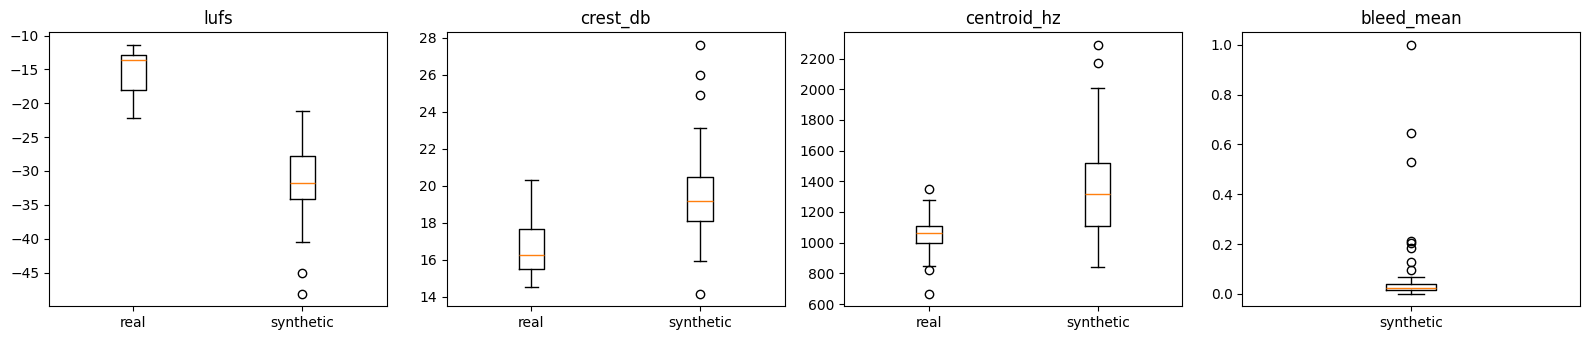

,centroid_hz,lufs,bleed
origin,synthetic,synthetic,synthetic
instrument,,,
Bassoon,957.6,-45.6,0.0
Cello,1037.9,-34.5,0.0
Clarinet,1175.2,-37.7,0.0
Flute,1078.7,-32.2,0.1
Oboe,1270.0,-36.3,0.0
Sax,1754.9,-38.5,0.1
Viola,1537.1,-43.5,0.1
Violin,2176.2,-38.1,0.0


In [18]:
metrics = [m for m in ['lufs', 'crest_db', 'centroid_hz', 'bleed_mean'] if m in stats_df and stats_df[m].notna().any()]
fig, axes = plt.subplots(1, len(metrics), figsize=(4 * len(metrics), 3.5), squeeze=False)
for ax, m in zip(axes[0], metrics):
    groups = [(o, g[m].dropna()) for o, g in stats_df.groupby('origin') if g[m].notna().any()]
    ax.boxplot([g for _, g in groups]); ax.set_xticks(range(1, len(groups) + 1), [o for o, _ in groups]); ax.set_title(m)
plt.tight_layout(); plt.show()

if len(stem_df):
    display(stem_df.groupby(['instrument', 'origin'])[['centroid_hz', 'lufs', 'bleed']].mean().round(1).unstack('origin'))

3e. Save the tables to Drive

In [19]:
out = Path('/content/drive/MyDrive/Cadenza Challenge/results/06_data_loader')
if not Path('/content/drive/MyDrive').exists():
    out = Path('/content/results_06'); print('Drive not mounted - saving locally only')
out.mkdir(parents=True, exist_ok=True)
check_df.to_csv(out / 'valid_checks.csv', index=False)
if 'diag_df' in globals(): diag_df.to_csv(out / 'valid_failures_diagnosis.csv', index=False)
if 'train_check_df' in globals(): train_check_df.to_csv(out / 'train_checks.csv', index=False)
origin_df.to_csv(out / 'song_origins.csv', index=False)
stats_df.to_csv(out / 'scene_stats.csv', index=False)
stem_df.to_csv(out / 'stem_stats.csv', index=False)
print('saved to', out, sorted(p.name for p in out.iterdir()))

saved to /content/drive/MyDrive/Cadenza Challenge/results/06_data_loader ['scene_stats.csv', 'song_origins.csv', 'stem_stats.csv', 'train_checks.csv', 'valid_checks.csv', 'valid_failures_diagnosis.csv']


**Step 3 notes (fill in):**
- Datasets per split: ___
- Real recordings available? ___ (eval only? stems or mixtures only?) What the Cadenza page calls the tuning set: ___
- Biggest real vs synthetic differences (loudness / crest / brightness / bleed): ___
- Why that could hurt the pretrained separators: ___
- Note: URMP players were recorded separately, so bleed may be low even for real data - report what the numbers show.